# PMU Hierarchical Classification System

This notebook implements a hierarchical classification system for PMU (Phasor Measurement Unit) data using successive binary classifiers.

## Overview
- Processes PMU waveform data from the user to extract statistical features
- Applies hierarchical classification (Primary → Secondary → Tertiary)
- Visualizes classification results with nested pie charts
- Analyzes feature importance across different classification levels

## Table of Content
1. Import Required Libraries
2. Global Variables and Configuration
3. Load Configuration and Dictionaries
4. Core Functions

    4.1 Successive Binary Classifier

    4.2. Validation Function

    4.3. Visualization Functions

    4.4. Pychart Generation

    4.5. Feature Importance Vizual

    4.6. Data Preprocessing Function

5. Load and Validate Input Data
6. Input Data Analysis
7. Main Analysis Visualization and Results


## Things to do:

1. Importance graph hirearcal vizualisation decending order. 
2. Missing data clarification
3. Add results for a comprative analysis within the different models tested as well as the data augmentation techniques for the user. 



## 1. Import Required Libraries

In [48]:
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

# Pickling
import pickle

# Data formats
import json

# Disable Pandas Warnings for Future
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# Disable Scikit-Learn  
import warnings
from sklearn.exceptions import InconsistentVersionWarning

warnings.filterwarnings("ignore", category=InconsistentVersionWarning)

# Display settings
pd.set_option('display.max_rows', None) 
pd.set_option('display.max_columns', None)

# For better plots in notebook
%matplotlib inline

## 2. Global Variables and Configuration

In [49]:
# Initialize global variables
data_type = 'PMU'
nFeatures = 6
nPMU = None  # Will be calculated based on input data

# File paths
INPUT_FILE = 'Inputs/sigId-1962.csv'
PRI_TO_SEC_DICT_FILE = 'Inputs/pri_to_sec_dict_transmission.json'
SEC_TO_TERT_DICT_FILE = 'Inputs/sec_to_tert_dict_transmission.json'
CLASSIFIER_PATH = 'Classifiers'

# Primary group labels
group_labels = ['Events', 'State', 'Equipment', 'Conditions', 'Phase']

## 3. Load Configuration and Dictionaries

In [50]:
# Load hierarchical mapping dictionaries
try:
    pri_to_sec_dict = json.load(open(PRI_TO_SEC_DICT_FILE))
    sec_to_tert_dict = json.load(open(SEC_TO_TERT_DICT_FILE))

    # Primary -> Secondary
    print("Successfully loaded mapping dictionaries From Primary layer to Secondary layer")
    display(pri_to_sec_dict)

    # Secondary -> Third
    print("\nSuccessfully loaded mapping dictionaries From Secondary layer to Third layer")
    display(sec_to_tert_dict)


# If the files not found print error
except FileNotFoundError as e:
    print(f"Error loading dictionaries: {e}")
    print("Please ensure the dictionary files are in the correct location")

Successfully loaded mapping dictionaries From Primary layer to Secondary layer


{'Events': ['Equipment-Failure',
  'Fault',
  'External',
  'System-Event-Condition',
  'Construction-&-Maintenance',
  'Protection-Event',
  'Switching-Event',
  'Other',
  'Vegetation',
  'Wildlife',
  'Defect-or-Deterioration'],
 'State': ['Change-State', 'Steady-State'],
 'Conditions': ['Weather', 'Natural-disaster'],
 'Equipment': ['Substation',
  'Overhead-Equipment',
  'Interrupting-Device',
  'Sources',
  'Transformer',
  'Devices'],
 'Phase': ['Two-phase',
  'Single-phase-ground',
  'Three-phase',
  'Single-phase',
  'Two-phase-ground']}


Successfully loaded mapping dictionaries From Secondary layer to Third layer


{'System-Event-Condition': ['Frequency-Deviation',
  'Oscillation',
  'Nonspecific-System-Event-Condition'],
 'External': ['Lightning-Strike', 'Nonspecific-External'],
 'Equipment-Failure': ['Nonspecific-Equipment-Failure', 'Transformer-Failure'],
 'Fault': ['Nonspecific-Fault'],
 'Construction-&-Maintenance': ['Maintenance',
  'Accident',
  'Nonspecific-Construction-&-Maintenance'],
 'Switching-Event': ['Nonspecific-Switching-Event'],
 'Vegetation': ['Tree'],
 'Other': ['Fire'],
 'Defect-or-Deterioration': ['Contamination'],
 'Wildlife': ['Nonspecific-Wildlife'],
 'Protection-Event': ['Nonspecific-Protection-Event'],
 'Steady-State': ['Nonspecific-Steady-State'],
 'Change-State': ['Trip'],
 'Overhead-Equipment': ['Conductor',
  'Nonspecific-Overhead-Equipment',
  'Arrester'],
 'Sources': ['Generator', 'Wind'],
 'Interrupting-Device': ['Nonspecific-Interrupting-Device'],
 'Transformer': ['Nonspecific-Transformer'],
 'Substation': ['Transmission'],
 'Devices': ['Capacitor'],
 'Weather':

## 4. Core Functions

### 4.1 Successive Binary Classifier

Function that inputs the features of a single test sample to the binary classifiers associated with each label in the input label_list.
1. param test_features: The features for a single test sample.
2. param label_list: Each label in the label_list should have an associated binary classifier and test_features will be inputted to each of these binary classifiers. 
3. param path_to_read: Specifies the directory to find the pickled classifier. Right now, this assumes that the path_to_read is in the directory `Classifiers/Transmission_PMU` by default and that there is a file or files named `RF_{evttag}` where evttag is the event tag label. 
4. return: The predicted class after getting the maximum positive probabilities outputted by each binary classifier representing each label in label_list. 
    

In [51]:
def successive_binary_classifier(test_features: pd.DataFrame, label_list: list, path_to_read: str = 'Classifiers') -> str:

    # Create an empty DataFrame with two columns
    df_prediction = pd.DataFrame(columns=["label", "raw_prob"])


    # Create another empty DataFrame with three columns
    df_importance = pd.DataFrame(columns=["label", "feature", "importance"])

    for evttag in label_list:

        # For each label, open and load a pickled Random Forest model
        with open('{}/RF_{}.pickle'.format(path_to_read, evttag), 'rb') as handle:
            rf = pickle.load(handle) # Trained rf model

            #Use the loaded model to predict class probabilities on test_features.
            proba = rf.predict_proba(test_features)
            df_prediction.loc[len(df_prediction)] = [evttag, proba[0][1]]

            #Get feature importances from the model.
            importances = rf.feature_importances_
            feature_names = test_features.columns.tolist()
            importance_df = pd.DataFrame({'feature': feature_names,'importance': importances}).sort_values(by='importance', ascending=False).reset_index(drop=True)
            importance_df['label'] = evttag

            #Append the current model's feature importances to the overall df_importance DataFrame.
            df_importance = pd.concat([df_importance, importance_df], ignore_index=True)

    #-----------------------------------------------#  

    #$$$print("\n\n\n++++++The Data Prediction:\n\n" , df_prediction)
    #$$$print("\n\n\n++++++The Importance is:\n\n",df_importance)
        
    # Creates a new column by dividing the raw_probabilities by the sum of all the raw_probabilities
    df_prediction['adj_prob'] = df_prediction['raw_prob'] / df_prediction['raw_prob'].sum()
    #$$$print("\n\n\n++++++The prediction:\n\n",df_prediction)

    #keep only probabilites that are at least 0.05 or 5% or higher the rest are discarded
    df_prediction = df_prediction[df_prediction['adj_prob'] >= 0.05]
    #$$$print("\n\n\n++++++The Prediction:\n\n",df_prediction)

    # The remaining adj_prob values are divided by their new sum, so that the probabilities once again sum to 1.
    df_prediction['adj_prob'] = df_prediction['adj_prob'] / df_prediction['adj_prob'].sum()
    #$$$print("\n\n\n++++++The Prediction:\n\n",df_prediction)

    # Checks if there are more than 3 different rows in "df_predictions" if so it filter them out and normilizes the probabilities to rach 1 again.
    if df_prediction.shape[0] > 3:
        df_prediction = df_prediction.nlargest(3,'adj_prob').reset_index(drop=True)
    df_importance = df_importance[df_importance['label'].isin(df_prediction['label'].tolist())]

    return df_prediction, df_importance

### 4.2 Validation Function

Function that runs all the signatures in the testing dataset in a way that is inherently hierarchical. In particular, this function will follow the local classifier per node (LCN) approach, assuming that the Class label that is first predicted is correct, i.e. the predicted Class label will be used to predict the Sub-Class label regardless of correctness of Class label.
1. param df: The DataFrame that contains features, labels, and other identifying columns such as Signature ID.
2. param group_label: A string that defines which Group label to focus on.
3. return: A DataFrame that contains all the actual versus predicted Class and Sub-Class.


In [52]:
def validation(df: pd.DataFrame, group_label: str) -> tuple[pd.DataFrame, float, float, float, float] :


    # Create empty list used later on the code
    importance_indices = {}

    # Copy the original df with the statistical values for each input PMU to avoid overwritting the original one
    df1 = df.copy().dropna().reset_index()

    # Maps out first layer to secondary layer
    arr_class = np.asanyarray(pri_to_sec_dict[group_label])
    #$$$print("\n\n\n++++++The arry class is:\n\n",arr_class)

    # Indexes the first two columns.
    x_test = df1.iloc[:, 2:]
    #print("\n\n\n ++++++The X_test is:\n\n",x_test)
    
    df_pred_subclass_result = None
    
    for idx in x_test.index:
        
        #print("Testing for Sig ID {}".format(df1.iloc[idx]["sigid"]))
        test_features = x_test[x_test.index == idx]
        df_pred_class_result, df_pred_class_impt_analysis = successive_binary_classifier(test_features, arr_class)
        
        #print("\n\n\n ++++++The predicted class results are:\n\n",df_pred_class_result)
        #print("\n\n\n ++++++The predicted class imp is :\n\n",df_pred_class_impt_analysis)

        #Itirates over the value Label 
        for col in df_pred_class_impt_analysis['label'].unique():

            # Checks if the urrent label is already a key in the inportance_indices
            if col not in importance_indices:
                # If not nested dictionaries are initialized
                importance_indices[col] = {}
                importance_indices[col]['instance'] = {}

            # This for loop the features importances are set to a single row with its correspoding importance
            for ind,row in df_pred_class_impt_analysis[df_pred_class_impt_analysis['label'] == col].iterrows():
                importance_indices[col]['instance'][row['feature']] = row['importance']
            
            #$$$print("\n\n\n ++++++The importance indices is:\n\n",importance_indices)

        # Runs a second classifier
        for label in df_pred_class_result['label']:
            #Mapping from the current laberl (2nd) to the list of tertiary classes
            pred_subclass_1, pred_subclass_impt_analysis = successive_binary_classifier(test_features, sec_to_tert_dict[label])
            
            #$$$print("\n\n\n++++++The pred subclass:\n\n",pred_subclass_1)
            #$$$print("\n\n\n++++++The pred sbu class impt analysis \n\n",pred_subclass_impt_analysis)

            # Nested Dictionary
            for col in pred_subclass_impt_analysis['label'].unique():
                importance_indices[label][col] = {}

                for ind,row in pred_subclass_impt_analysis[pred_subclass_impt_analysis['label'] == col].iterrows():
                    importance_indices[label][col][row['feature']] = row['importance']

                #$$$print("\n\n\n The Importance Indices is:\n\n",importance_indices)

            #Raneme the "Label" to tertianry label "tert_label"
            pred_subclass_1.rename(columns={'label': 'tert_label'}, inplace=True)

            #Adds a new column 'sec_label' to pred_subclass_1, setting its value to the current secondary class label (label from the outer loop).
            pred_subclass_1['sec_label'] = label
        
            #Add a new column with the name of the secondary layter tag ID that its matting with the respective probability
            pred_subclass_1.insert(0, 'sec_label', pred_subclass_1.pop('sec_label'))

            # For the first iteration only of the loop
            if df_pred_subclass_result is None:
                df_pred_subclass_result = pred_subclass_1
            #Accumulate all tertiary predictions and their associated secondary labesl into a data DataFrame
            else:
                df_pred_subclass_result = pd.concat([df_pred_subclass_result, pred_subclass_1], axis=0)

    return df_pred_class_result, df_pred_subclass_result, importance_indices

### 4.3 Visualization Functions

The vis_result function generates a nested pie chart to visualize the likelihood distribution of primary, secondary, and tertiary labels. It takes three input arguments:
1. pri_label: The primary label whose likelihood distribution is being visualized.
2. sec_res: A Pandas DataFrame containing secondary labels and their adjusted probabilities (adj_prob).
3. tert_res: A Pandas DataFragme containing tertiary labels, their associated secondary labels, and their adjusted probabilities (adj_prob).


In [53]:
def vis_result(pri_label, sec_res, tert_res):

    sec_res = sec_res.reset_index(drop=True)
    valsArr = []
    inner_sizes = []
    inner_labels = []
    inner_labels_on_fig =[]
    inner_labels_each_tert_group = []
    inner_color_arr = []
    legend_labels_reodered = []
    legend_index_reodered =[]


    sec_prob = [x / sum(sec_res['adj_prob'].tolist()) for x in sec_res['adj_prob'].tolist()]
    outer_sizes = [round(x, 3) for x in sec_prob]
    outer_labels = sec_res['label'].tolist()


    for ind, label in enumerate(outer_labels):
        outer_labels[ind] = label + ': ' + str(round(sec_prob[ind]*100,1)) + '%'
    outer_labels_on_fig = outer_labels
    sorted_prob_sec_label_index = [i for i, _ in sorted(enumerate(sec_prob), key=lambda x: x[1], reverse=True)]
    outer_labels = [outer_labels[i] for i in sorted_prob_sec_label_index]


    for indSecLayer, rowSec in sec_res.iterrows():
        df_slc_sec_label = tert_res[tert_res['sec_label'] == rowSec['label']]
        tert_prob = [round(x, 4) for x in df_slc_sec_label['adj_prob'].tolist()]
        prob_for_label = [x * 100 for x in tert_prob]
        tert_labels = []


        for ind, label in enumerate(df_slc_sec_label['tert_label']):
            inner_labels.append(label + ': ' + str(round(prob_for_label[ind],1)) + '%')
            tert_labels.append(label + ': ' + str(round(prob_for_label[ind],1)) + '%')
            inner_labels_on_fig.append(str(round(prob_for_label[ind],1)) + '%')


        sorted_prob_tert_label_index = [i for i, _ in sorted(enumerate(prob_for_label), key=lambda x: x[1], reverse=True)]
        ordered_tert_labels = [tert_labels[i] for i in sorted_prob_tert_label_index]
        inner_labels_each_tert_group.append(ordered_tert_labels)
        inner_sizes.extend([x * outer_sizes[indSecLayer] / sum(tert_prob) for x in tert_prob])
        inner_color_arr.extend(list(range(indSecLayer*4 + 1,indSecLayer*4 + 1 + len(tert_prob))))
 
    
    inner_labels_each_tert_group = [inner_labels_each_tert_group[i] for i in sorted_prob_sec_label_index]
    for idx,sec_label in enumerate(outer_labels):
        legend_labels_reodered.append(sec_label)
        legend_labels_reodered.extend(inner_labels_each_tert_group[idx])
    
    legend_labels = outer_labels + inner_labels
    for label in legend_labels_reodered:
        legend_index_reodered.append(legend_labels.index(label))
    

    fig, ax = plt.subplots(figsize=(16,9))
    cmap = plt.colormaps["tab20c"]
    outer_colors = cmap(np.arange(len(outer_sizes))*4)
    inner_colors = cmap(inner_color_arr)
 
    if data_type == 'PMU' and pri_label == 'Phase':
        legend_labels = outer_labels
        legend_index_reodered = [x for x in legend_index_reodered if x < len(legend_labels)]
        outer_pi_width = 0.8

    else:
        inner_pie = ax.pie(inner_sizes, 
                        radius = 0.8,
                        labels = inner_labels_on_fig,
                        labeldistance = 0.5, 
                        colors = inner_colors, 
                        wedgeprops=dict(width = 0.5, edgecolor='w'),
                        textprops = {'fontsize': 8})
        legend_labels = outer_labels + ["  -- " + item for item in inner_labels]
        outer_pi_width = 0.2

    outer_pie = ax.pie(outer_sizes, 
                    radius = 1, 
                    labels = outer_labels_on_fig, 
                    labeldistance = 1.1, 
                    colors = outer_colors, 
                    wedgeprops = dict(width=outer_pi_width, edgecolor='w'), 
                    textprops = {'fontsize': 14, 'weight': 'bold'})
        
    handles, labels = ax.get_legend_handles_labels() 
    ordered_handles = [handles[i] for i in legend_index_reodered]
    ordered_labels = [legend_labels[i] for i in legend_index_reodered]

    value_to_index = {value: idx for idx, value in enumerate(outer_labels_on_fig)}
    mapping = [value_to_index[val] for val in outer_labels]
    outer_color_index = (np.arange(len(outer_sizes))*4).tolist()
    ordered_outer_color_index =  [outer_color_index[i] for i in mapping]
    color_code = []
    ct_sec_label = -1
    ct_tert_label = 1

    for tag in ordered_labels:
        if tag in outer_labels:
            ct_sec_label = ct_sec_label + 1
            color_code.append(ordered_outer_color_index[ct_sec_label])
            ct_tert_label = 1
            
        else:
            color_code.append(ordered_outer_color_index[ct_sec_label] + ct_tert_label)
            ct_tert_label = ct_tert_label + 1
    ordered_colors = cmap(color_code)

    test_handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=ordered_colors[i],
              markersize=10)
    for i in range(len(ordered_labels))]

    ax.legend(test_handles, 
              ordered_labels, 
              loc="upper left", 
              bbox_to_anchor = (1, 0, 0.5, 1))   

    ax.set(aspect="equal")
    plt.title('Likelihood for the Primary Label: ' + pri_label, 
              fontweight='bold', 
              fontsize=20) 
    plt.tight_layout()
    plt.show()

## 4.4 Pychart Generation

Generate the nested pie chart of primary/secondary/tertiary likelihoods and, optionally, display the secondary/tertiary prediction tables for a given PMU.

#### Parameters

1. pri_label : str 
Primary label displayed in the chart title (and affects a Phase/PMU special case).
    
2. sec_res : pandas.DataFrame
Columns expected: ['label', 'adj_prob'] for the secondary layer.
    
3. tert_res : pandas.DataFrame
Columns expected: ['sec_label', 'tert_label', 'adj_prob'] for the tertiary layer.
    
4. results : list[dict] | None
Your results structure. If provided, tables for the specified PMU are printed.
    
5. pmu_index : int
 Which PMU from `results` to display.
    
6. groups_order : list[str] | None
Order to iterate over groups. Defaults to ['Events','State','Equipment','Conditions','Phase'].
    
7. show_tables : bool
Whether to display the tables beneath the chart.

8. data_type : str
Used to preserve your special-case behavior for ('PMU','Phase').

9. figure_size : tuple[int, int]
Matplotlib figure size.


In [54]:
# --- one-cell version: plot + tables ---
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def vis_result(
    pri_label,
    sec_res,
    tert_res,
    *,
    results=None,            # pass your `results` list here to show tables
    pmu_index=0,             # which PMU to show (0-based)
    groups_order=None,       # custom order; default matches your original if None
    show_tables=True,        # toggle table printing
    data_type='PMU',         # matches your original logic (e.g., 'PMU')
    figure_size=(16, 9)      # tweakable figure size
):

    # -----------------------------
    # plotting (based on your code)
    # -----------------------------
    sec_res = sec_res.reset_index(drop=True)

    inner_sizes = []
    inner_labels = []
    inner_labels_on_fig = []
    inner_labels_each_tert_group = []
    inner_color_arr = []
    legend_labels_reodered = []
    legend_index_reodered = []

    # guard: avoid division by zero if all adj_prob are 0
    sec_adj = sec_res['adj_prob'].tolist()
    sec_sum = sum(sec_adj) if sum(sec_adj) > 0 else 1.0
    sec_prob = [x / sec_sum for x in sec_adj]

    outer_sizes = [round(x, 3) for x in sec_prob]
    outer_labels = sec_res['label'].tolist()

    for ind, label in enumerate(outer_labels):
        outer_labels[ind] = label + ': ' + str(round(sec_prob[ind] * 100, 1)) + '%'
    outer_labels_on_fig = outer_labels.copy()

    sorted_prob_sec_label_index = [i for i, _ in sorted(enumerate(sec_prob), key=lambda x: x[1], reverse=True)]
    outer_labels = [outer_labels[i] for i in sorted_prob_sec_label_index]

    for indSecLayer, rowSec in sec_res.iterrows():
        df_slc_sec_label = tert_res[tert_res['sec_label'] == rowSec['label']]
        tert_prob = [round(x, 4) for x in df_slc_sec_label['adj_prob'].tolist()]
        sum_tert = sum(tert_prob) if sum(tert_prob) > 0 else 1.0

        prob_for_label = [x * 100 for x in tert_prob]
        tert_labels = []
        for ind, label in enumerate(df_slc_sec_label['tert_label']):
            label_pct = str(round(prob_for_label[ind], 1)) + '%'
            inner_labels.append(f"{label}: {label_pct}")
            tert_labels.append(f"{label}: {label_pct}")
            inner_labels_on_fig.append(label_pct)

        sorted_prob_tert_label_index = [i for i, _ in sorted(enumerate(prob_for_label), key=lambda x: x[1], reverse=True)]
        ordered_tert_labels = [tert_labels[i] for i in sorted_prob_tert_label_index]
        inner_labels_each_tert_group.append(ordered_tert_labels)

        # share of each tert wedge within its secondary slice
        inner_sizes.extend([x * outer_sizes[indSecLayer] / sum_tert for x in tert_prob])

        # color indexing relies on tab20c groups of 4; expand if needed
        inner_color_arr.extend(list(range(indSecLayer * 4 + 1, indSecLayer * 4 + 1 + len(tert_prob))))

    # reorder tert groups to match sorted secondary labels
    inner_labels_each_tert_group = [inner_labels_each_tert_group[i] for i in sorted_prob_sec_label_index]
    for idx, sec_label in enumerate(outer_labels):
        legend_labels_reodered.append(sec_label)
        legend_labels_reodered.extend(inner_labels_each_tert_group[idx])

    legend_labels = outer_labels + inner_labels
    for label in legend_labels_reodered:
        # .index is safe here because legend_labels was built from these
        legend_index_reodered.append(legend_labels.index(label))

    fig, ax = plt.subplots(figsize=figure_size)
    cmap = plt.colormaps["tab20c"]
    outer_colors = cmap(np.arange(len(outer_sizes)) * 4)
    inner_colors = cmap(inner_color_arr) if inner_color_arr else None

    # special case preserved
    if data_type == 'PMU' and pri_label == 'Phase':
        legend_labels = outer_labels
        legend_index_reodered = [x for x in legend_index_reodered if x < len(legend_labels)]
        outer_pi_width = 0.8
    else:
        if inner_sizes:
            ax.pie(
                inner_sizes,
                radius=0.8,
                labels=inner_labels_on_fig,
                labeldistance=0.5,
                colors=inner_colors,
                wedgeprops=dict(width=0.5, edgecolor='w'),
                textprops={'fontsize': 8}
            )
        legend_labels = outer_labels + ["  -- " + item for item in inner_labels]
        outer_pi_width = 0.2

    ax.pie(
        outer_sizes,
        radius=1,
        labels=outer_labels_on_fig,
        labeldistance=1.1,
        colors=outer_colors,
        wedgeprops=dict(width=outer_pi_width, edgecolor='w'),
        textprops={'fontsize': 14, 'weight': 'bold'}
    )

    # build ordered legend with color mapping
    value_to_index = {value: idx for idx, value in enumerate(outer_labels_on_fig)}
    mapping = [value_to_index[val] for val in outer_labels]
    outer_color_index = (np.arange(len(outer_sizes)) * 4).tolist()
    ordered_outer_color_index = [outer_color_index[i] for i in mapping]

    color_code = []
    ct_sec_label = -1
    ct_tert_label = 1

    ordered_labels = [legend_labels[i] for i in legend_index_reodered]
    for tag in ordered_labels:
        if tag in outer_labels:
            ct_sec_label += 1
            color_code.append(ordered_outer_color_index[ct_sec_label])
            ct_tert_label = 1
        else:
            color_code.append(ordered_outer_color_index[ct_sec_label] + ct_tert_label)
            ct_tert_label += 1

    ordered_colors = cmap(color_code) if color_code else []

    test_handles = [
        plt.Line2D([0], [0], marker='o', color='w',
                   markerfacecolor=ordered_colors[i] if len(ordered_colors) > i else 'w',
                   markersize=10)
        for i in range(len(ordered_labels))
    ]

    if ordered_labels:
        ax.legend(test_handles, ordered_labels, loc="upper left", bbox_to_anchor=(1, 0, 0.5, 1))

    ax.set(aspect="equal")
    plt.title('Likelihood for the Primary Label: ' + str(pri_label), fontweight='bold', fontsize=20)
    plt.tight_layout()
    plt.show()

    # ---------------------------------
    # optional: print result tables here
    # ---------------------------------
    if show_tables and isinstance(results, (list, tuple)) and len(results) > pmu_index:
        pmu = results[pmu_index]
        if groups_order is None:
            groups_order = ['Events', 'State', 'Equipment', 'Conditions', 'Phase']

        for grp in groups_order:
            if grp in pmu:
                display(Markdown(f"<br><br>### PMU {pmu_index+1} — {grp} Classification Results"))
                if isinstance(pmu[grp], dict):
                    if 'pred_class' in pmu[grp]:
                        display(Markdown("**Secondary predictions:**"))
                        display(pmu[grp]['pred_class'])
                    if 'pred_subclass' in pmu[grp]:
                        display(Markdown("**Tertiary predictions:**"))
                        display(pmu[grp]['pred_subclass'])



## 4.5 Feature Importance Vizual

Visualize feature importance scores for secondary labels

Grouped-importance plot with per-family metric ordering by a chosen label.
Usage example (at bottom of cell):

1. data, "events",
2. sort_groups_by="family_importance",   # keeps families together
3. family_agg="sum",
4. family_sort="prefix",                 # or "importance"
5. metric_sort="by_label",               # <= sort the 4 metrics inside each family by this label
6. metric_sort_label="Fault",            # <= the label that drives descending order



In [55]:

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# --- helpers ---------------------------------------------------------------

def _sequential_colors(n, palette="magma", reverse=False):
    """Return n colors from a sequential palette (matplotlib fallback if seaborn absent)."""
    try:
        import seaborn as sns
        colors = sns.color_palette(palette, n_colors=n)
    except Exception:
        cmap = plt.get_cmap(palette)
        colors = [cmap(i/(max(1, n-1))) for i in range(n)]
    if reverse:
        colors = list(reversed(colors))
    return colors


def _order_numeric(series_or_df, how, axis=None, descending=True):
    if how == "sum":      agg = series_or_df.sum(axis=axis)
    elif how == "mean":   agg = series_or_df.mean(axis=axis)
    elif how == "max":    agg = series_or_df.max(axis=axis)
    elif how == "min":    agg = series_or_df.min(axis=axis)
    else:
        raise ValueError("unknown 'how'")
    return agg.sort_values(ascending=not descending).index.tolist()


def _sort_by_prefix_and_metric(
    names,
    prefix_order=("f_","df_","vp_m_","vp_a_","ip_m_","ip_a_"),
    metric_order=("kurtosis","mean","skew","std")
):
    """Sort names like 'vp_m_kurtosis' into blocks by prefix, then by metric."""
    def prefix_rank(n):
        for i, p in enumerate(prefix_order):
            if n.startswith(p):
                return i
        return len(prefix_order)  # "Other"
    def metric_rank(n):
        suffix = n.split("_")[-1]
        try:
            return metric_order.index(suffix)
        except ValueError:
            return len(metric_order)
    return sorted(names, key=lambda n: (prefix_rank(n), metric_rank(n), n))


def _colors_by_prefix_metric(
    groups,
    prefix_order,
    metric_order,
    prefix_cmaps=None,
    metric_positions=(0.25, 0.45, 0.65, 0.85),
    reverse_prefix=None
):
    """
    Build a color for each 'group' using:
      - 6 distinct sequential colormaps for each prefix family
      - 4 shades (positions) within a colormap for the 4 metrics
    """
    # sensible defaults (6 families)
    default_cmaps = {
        "f_":   "Blues",
        "df_":  "Purples",
        "vp_m_":"Greens",
        "vp_a_":"Oranges",
        "ip_m_":"Reds",
        "ip_a_":"Greys",
    }
    if prefix_cmaps is None:
        prefix_cmaps = default_cmaps
    if reverse_prefix is None:
        reverse_prefix = set()

    metric_to_idx = {m:i for i, m in enumerate(metric_order)}

    cmap_cache = {}
    for p in prefix_order:
        cmap_name = prefix_cmaps.get(p, "viridis")
        if p in reverse_prefix or cmap_name.endswith("_r"):
            cmap = plt.get_cmap(cmap_name if cmap_name.endswith("_r") else cmap_name + "_r")
        else:
            cmap = plt.get_cmap(cmap_name)
        cmap_cache[p] = cmap

    colors = []
    for g in groups:
        p = next((p for p in prefix_order if g.startswith(p)), None)
        m = g.split("_")[-1]
        j = metric_to_idx.get(m, 0)
        pos = metric_positions[min(j, len(metric_positions)-1)]
        cmap = cmap_cache.get(p, plt.get_cmap("viridis"))
        colors.append(cmap(pos))
    return colors


def _order_groups_by_family_importance(
    df, groups, *,
    prefix_order=("f_","df_","vp_m_","vp_a_","ip_m_","ip_a_"),
    metric_order=("kurtosis","mean","skew","std"),
    family_agg="sum",
    family_sort="importance",       # "importance" | "prefix"
    metric_sort="importance",       # "importance" | "metric_order" | "by_label"
    metric_sort_label=None,         # used when metric_sort == "by_label"
    descending=True,
):
    """Return groups ordered by family order, then metric order per chosen strategy."""
    # group-level importance across labels
    if family_agg == "sum":      gimp = df[groups].sum(axis=0)
    elif family_agg == "mean":   gimp = df[groups].mean(axis=0)
    elif family_agg == "max":    gimp = df[groups].max(axis=0)
    elif family_agg == "min":    gimp = df[groups].min(axis=0)
    else:
        raise ValueError("family_agg must be one of {'sum','mean','max','min'}")

    # bucket groups by prefix family
    fam_to_groups = {p: [] for p in prefix_order}
    others = []
    for g in groups:
        p = next((p for p in prefix_order if g.startswith(p)), None)
        (fam_to_groups[p].append(g) if p is not None else others.append(g))

    # family importance = sum of its members
    fam_scores = {
        p: float(gimp[fam_to_groups[p]].sum()) if fam_to_groups[p] else -np.inf
        for p in prefix_order
    }

    # order families
    if family_sort == "importance":
        fams_sorted = sorted(prefix_order, key=lambda p: fam_scores[p], reverse=descending)
    elif family_sort == "prefix":
        fams_sorted = list(prefix_order)
    else:
        raise ValueError("family_sort must be 'importance' or 'prefix'")

    # inside each family, order the four metrics
    metric_rank = {m:i for i,m in enumerate(metric_order)}
    df_by_label = df.set_index("label")
    if metric_sort == "by_label":
        if metric_sort_label is None or metric_sort_label not in df_by_label.index:
            raise ValueError(
                f"metric_sort_label='{metric_sort_label}' not found among labels: {list(df_by_label.index)}"
            )

    ordered = []
    for p in fams_sorted:
        members = fam_to_groups[p]
        if not members:
            continue
        if metric_sort == "importance":
            members = sorted(members, key=lambda g: float(gimp[g]), reverse=descending)
        elif metric_sort == "by_label":
            row = df_by_label.loc[metric_sort_label]
            members = sorted(members, key=lambda g: float(row.get(g, 0.0)), reverse=descending)
        elif metric_sort == "metric_order":
            members = sorted(
                members,
                key=lambda g: metric_rank.get(g.split("_")[-1], len(metric_order))
            )
        else:
            raise ValueError("metric_sort must be one of {'importance','metric_order','by_label'}")
        ordered.extend(members)

    # handle groups without a known prefix
    others_sorted = sorted(others, key=lambda g: float(gimp[g]), reverse=descending)
    ordered.extend(others_sorted)
    return ordered


# --- main ------------------------------------------------------------------

def vis_importance(
    data,
    pri_label,
    *,
    sort_labels_by="sum",
    sort_groups_by="family_importance",   # families grouped; order controlled by family_sort
    descending=True,
    legend_prefix_order=("f_","df_","vp_m_","vp_a_","ip_m_","ip_a_"),
    metric_order=("kurtosis","mean","skew","std"),
    # single-palette fallback (kept for compatibility)
    palette="magma",
    reverse_palette=False,
    # multi-palette options
    use_family_palettes=True,
    prefix_cmaps=None,                    # dict like {"f_":"Blues", ...}
    metric_positions=(0.25, 0.45, 0.65, 0.85),
    reverse_prefix=None,                  # set of prefixes to reverse their ramps
    # family/metric ordering options
    family_agg="sum",                     # "sum" | "mean" | "max" | "min"
    family_sort="importance",             # "importance" | "prefix"
    metric_sort="importance",             # "importance" | "metric_order" | "by_label"
    metric_sort_label=None,               # used when metric_sort == "by_label"
):
    """
    Visualize importance scores with:
      - families (f_, df_, vp_m_, vp_a_, ip_m_, ip_a_) colored by distinct palettes,
      - 4 shades inside each family for (kurtosis, mean, skew, std),
      - family order by 'family_sort' (importance or prefix order),
      - metric order inside each family by 'metric_sort' (including 'by_label').
    """
    # ---------- build df ----------
    scond_labels = list(data.keys())
    df_scond_scores = pd.DataFrame({k: data[k]['instance'] for k in scond_labels})
    df = df_scond_scores.T.reset_index().rename(columns={"index": "label"}).fillna(0)
    groups = list(df.columns[1:])

    # ---------- order groups ----------
    if sort_groups_by == "custom":
        groups = _sort_by_prefix_and_metric(
            groups,
            prefix_order=legend_prefix_order,
            metric_order=metric_order
        )
    elif sort_groups_by == "family_importance":
        groups = _order_groups_by_family_importance(
            df, groups,
            prefix_order=legend_prefix_order,
            metric_order=metric_order,
            family_agg=family_agg,
            family_sort=family_sort,
            metric_sort=metric_sort,
            metric_sort_label=metric_sort_label,
            descending=descending
        )
    elif sort_groups_by == "alpha":
        groups = sorted(groups)
    elif sort_groups_by in {"sum","mean","max","min"}:
        groups = _order_numeric(df[groups], sort_groups_by, axis=0, descending=descending)
    else:
        raise ValueError("Unknown sort_groups_by")
    df = df[["label"] + groups]

    # ---------- sort labels (x-axis categories) ----------
    if sort_labels_by == "alpha":
        df = df.sort_values("label", ascending=True, kind="mergesort")
    elif sort_labels_by in {"sum","mean","max","min"}:
        order = _order_numeric(df[groups], sort_labels_by, axis=1, descending=descending)
        df = df.loc[order].reset_index(drop=True)

    labels = df["label"].tolist()
    x = np.arange(len(labels))
    width = 0.8 / max(1, len(groups))

    # ---------- colors ----------
    if use_family_palettes:
        color_list = _colors_by_prefix_metric(
            groups,
            legend_prefix_order,
            metric_order,
            prefix_cmaps=prefix_cmaps,
            metric_positions=metric_positions,
            reverse_prefix=reverse_prefix
        )
    else:
        color_list = _sequential_colors(len(groups), palette=palette, reverse=reverse_palette)

    fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)

    # draw bars
    for i, group in enumerate(groups):
        offset = (i - len(groups)/2) * width + width/2
        ax.bar(
            x + offset,
            df[group].values,
            width,
            label=group,
            color=color_list[i],
            edgecolor='black',
            linewidth=0.3
        )

    # axes cosmetics
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel("Values")
    ax.set_title("Importance Scores for Secondary Labels under: " + pri_label.upper())
    ax.margins(x=0.01)

    # legend
    proxies = [Patch(facecolor=c, edgecolor='black') for c in color_list]
    ax.legend(
        proxies, groups,
        loc='center left', bbox_to_anchor=(1.02, 0.5),
        frameon=True, ncol=1, borderaxespad=0.0, title="Features"
    )

    plt.show()



### 4.6 Data Preprocessing Function
    
Function to process the input time-series data into the required statistical data:
1. Normalize the data.
2. Calculate four statistical values (mean,std,skew,kurtosis) for each of the six power system measurements from the PMU raw data.
3. Returning a dataframe that can be fed into an ML model for signature matching.
    

In [56]:
def create_input_dataframe(raw_data):


    # Initilized two list used to store the statistical values as well as the names/labels
    sta_data = []
    sta_headers = []

    # Standardize features by removing the mean and scaling unit variance variables used in future work that will standardize any value
    scaler = StandardScaler()

    # Drop the time column form the .csv and keep the reast of the features
    data_values = raw_data.drop(columns=['Time']).values

    data_values_standardized = scaler.fit_transform(data_values)
    #print("\n\n\n++++++The data values standardized:\n\n",data_values_standardized)

    #Converts the standardized NumPy array back into a pandas DataFrame without the Time Column
    df_standardized = pd.DataFrame(data_values_standardized, columns=raw_data.drop(columns=['Time']).columns)

    for col in df_standardized.columns:
        if col != 'Time':
            sta_data.extend([df_standardized[col].mean(),
                             df_standardized[col].std(),
                             df_standardized[col].skew(),
                             df_standardized[col].kurtosis()])
            sta_headers.extend([col + '_mean', 
                                col + '_std',
                                col + '_skew',
                                col + '_kurtosis'])
            

    df = pd.DataFrame([pd.Series(sta_data).values], columns=sta_headers)
    #$$$print("\n\n\n +++++++The DataFrame:\n\n",df)

    
   
    # add a sig id feature to the data to identify PMU in the data starting with number 1
    df.insert(0 ,'sigid',['1'])

    # Builds a list of features names for use as DataFreame column Headers
    headers_feature_names = [s.split('.')[1] for s in df.columns.tolist()[1:]][0:24]
    headers_feature_names = ['sigid'] + headers_feature_names

    # Used if there is more than one PMU within the data 
    if int(nPMU) > 1:
        headers_pmu_names = [s.split('.')[0] for s in df.columns.tolist()[1:]]
        pmu_names = sorted(list(set(headers_pmu_names)))
        df_vals = df.iloc[0,1:].values
        df_reshape = np.reshape(df_vals, (-1, int (len(sta_headers) / nPMU)))
        rows = []
        
        for i, row in enumerate(df_reshape):
            new_id = pmu_names[i]  # Assign the row name from the list
            rows.append([new_id] + list(row))

        df = pd.DataFrame(rows, columns=headers_feature_names)

    # If just a single PMU just rename the headers of the column.
    else:
        df.columns = headers_feature_names
    return df

## 5. Load and Validate Input Data

In [57]:
# Load input PMU data provided by the user
try:
    #Input data file
    df_input = pd.read_csv(INPUT_FILE)
    #
    print(f"Successfully loaded input file: {INPUT_FILE}")
    print(f"\nShape of the data set(rows, columns): {df_input.shape}")
    print(f"\nColumns syntax: {list(df_input.columns)}")
    
    # Validate PMU data
    nPMU = ((df_input.shape[1]) - 1) / nFeatures
    if nPMU % 1 != 0:
        print('ERROR: Please check the number of features in the PMU data. Each PMU should have exactly SIX features in the columns.')
    else:
        print(f"\nNumber of distinct PMUs: {int(nPMU)} PMU entries.\n")
        
except FileNotFoundError:
    print(f"Error: Input file '{INPUT_FILE}' not found.")
    print("Please ensure the file is in the correct location.")

Successfully loaded input file: Inputs/sigId-1962.csv

Shape of the data set(rows, columns): (7200, 7)

Columns syntax: ['Time', 'P001.df', 'P001.f', 'P001.ip_a', 'P001.ip_m', 'P001.vp_a', 'P001.vp_m']

Number of distinct PMUs: 1 PMU entries.



## 6. Input Data Analysis

You can modify the cells below to analyze different aspects of the data or test individual components.

In [61]:
#Preview the input data 
    #Print the first rows of the data to get an understanding of how it looks like
if 'df_input' in locals():
    print("First 5 rows of input data from the input file:")
    display(df_input.head().round(3))
    
# Statristical values about the input data
    print("\nData statistics:\nCount: Number of Entries\nmean: Average value\nstd: Standard deviation\nmin: Minimum value\n25%: 25th percentile (first quartile)\n50%: 50th percentile (median)\n75%: 75th percentile (third quartile)\nmax: Maximum value")
    display(df_input.describe().round(3))

First 5 rows of input data from the input file:


,Time,P001.df,P001.f,P001.ip_a,P001.ip_m,P001.vp_a,P001.vp_m
0,0.000,0.0,59.995,-154.781,4.682,23.861,1.024
1,0.033,0.0,59.995,-154.845,4.683,23.802,1.024
2,0.067,0.0,59.995,-154.896,4.682,23.756,1.024
3,0.100,0.0,59.996,-154.940,4.684,23.703,1.024
4,0.133,0.0,59.995,-154.998,4.683,23.653,1.024



Data statistics:
Count: Number of Entries
mean: Average value
std: Standard deviation
min: Minimum value
25%: 25th percentile (first quartile)
50%: 50th percentile (median)
75%: 75th percentile (third quartile)
max: Maximum value


,Time,P001.df,P001.f,P001.ip_a,P001.ip_m,P001.vp_a,P001.vp_m
count,7200.000,7200.000,7200.000,7200.000,7200.000,7200.000,7200.000
mean,119.983,0.000,59.998,78.435,4.681,-67.267,1.024
std,69.287,0.027,0.004,84.888,0.007,36.524,0.000
min,0.000,-1.610,59.923,-179.970,4.648,-115.663,1.004
25%,59.992,0.000,59.996,83.761,4.677,-94.808,1.024
50%,119.983,0.000,59.998,91.858,4.682,-75.830,1.024
75%,179.975,0.000,60.000,122.082,4.686,-52.038,1.024
max,239.967,1.230,60.028,179.944,4.735,23.861,1.025


Block of code used for testing purpuses. Only needed for more indept perspective on the dataset.


In [62]:

# Block of code used for testing purpuses. Only needed for more indept perspective on the dataset.
#Test data preprocessing on a subset
if 'df_input' in locals():
    # You can test with a smaller subset first
    test_subset = df_input.head(5)  # First 100 rows
    print("Testing preprocessing on subset...")
    df_test_processed = create_input_dataframe(test_subset)
    print("\nProcessed data:")
    display(df_test_processed.round(3))



Testing preprocessing on subset...

Processed data:


,sigid,df_mean,df_std,df_skew,df_kurtosis,f_mean,f_std,f_skew,f_kurtosis,ip_a_mean,ip_a_std,ip_a_skew,ip_a_kurtosis,ip_m_mean,ip_m_std,ip_m_skew,ip_m_kurtosis,vp_a_mean,vp_a_std,vp_a_skew,vp_a_kurtosis,vp_m_mean,vp_m_std,vp_m_skew,vp_m_kurtosis
0,1,0.0,0.0,0.0,0.0,0.0,1.118,2.236,5.0,-0.0,1.118,0.124,-0.706,0.0,1.118,-0.192,-2.468,0.0,1.118,0.075,-1.011,0.0,1.118,-0.066,-2.302


## 7. Main Analysis Visualization and Results

Main function that runs signature matching process and provide graphical results. 

 Grouped-importance plot with per-family metric ordering by a chosen label.
 Usage example (at bottom of cell):
 vis_importance
1. data, "events",
2. sort_groups_by="family_importance",   # keeps families together
3. family_agg="sum",
4. family_sort="prefix",                 # or "importance"
5. metric_sort="by_label",               # <= sort the 4 metrics inside each family by this label
6. metric_sort_label="Fault",            # <= the label that drives descending order



In [64]:
def main():
    """
    Main function that runs signature matching process and provide graphical results. 
    """
    
    df_all_pmu = create_input_dataframe(df_input)
    
    print("Starting hierarchical classification...")
    print(f"Processing {len(df_all_pmu)} PMU signatures")
    print(f"Group labels to analyze: {group_labels}")
    
    # Store results for each PMU and group
    all_results = []
    
    for ind, row in df_all_pmu.iterrows():
        df = pd.DataFrame(row).T
        pmu_results = {}
        
        for pri_label in group_labels:
            print(f"\n{'='*50}")
            print(f"Processing PMU {ind+1}/{len(df_all_pmu)} - Primary Label: {pri_label}")
            print(f"{'='*50}")
            
            try:
                pred_class, pred_subclass, importance_scores = validation(df, pri_label)
                
                # Store results
                pmu_results[pri_label] = {
                    'pred_class': pred_class,
                    'pred_subclass': pred_subclass,
                    'importance_scores': importance_scores
                }
                
                # Visualize results
                vis_result(pri_label, pred_class, pred_subclass)
                print("\nSecondary probabilities:")
                display(pred_class.round(3))
                print("\nTertiary probabilities:")
                display(pred_subclass.round(3))
                print("\n\n")

                vis_importance(importance_scores, pri_label)
                

                
            except Exception as e:
                print(f"Error processing {pri_label}: {str(e)}")
                continue
        
        all_results.append(pmu_results)
    
    return all_results

Starting hierarchical classification...
Processing 1 PMU signatures
Group labels to analyze: ['Events', 'State', 'Equipment', 'Conditions', 'Phase']

Processing PMU 1/1 - Primary Label: Events


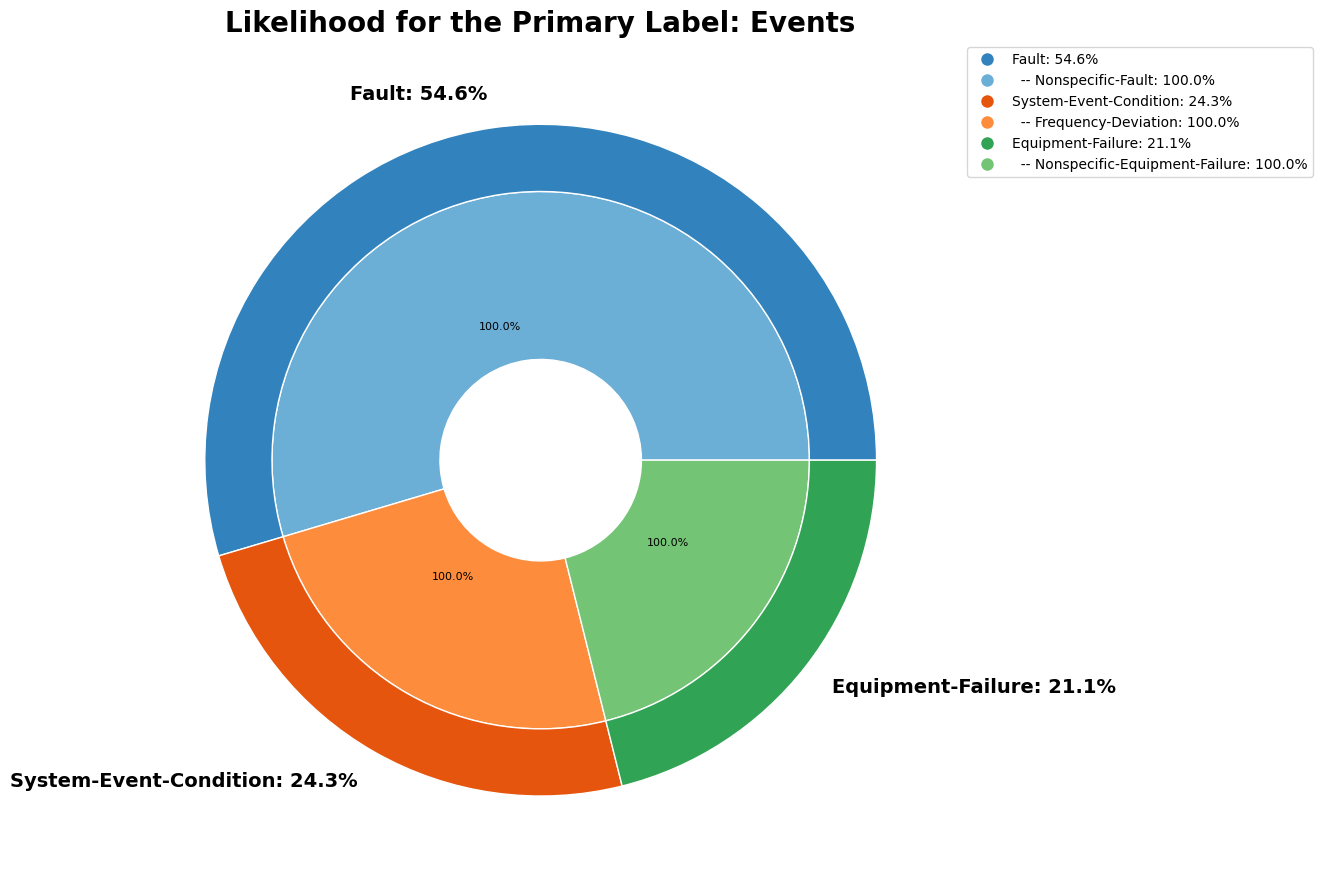


Secondary probabilities:


,label,raw_prob,adj_prob
0,Fault,0.585,0.410
1,System-Event-Condition,0.260,0.182
2,Equipment-Failure,0.226,0.158



Tertiary probabilities:


,sec_label,tert_label,raw_prob,adj_prob
0,Fault,Nonspecific-Fault,0.585,1.0
0,System-Event-Condition,Frequency-Deviation,0.290,1.0
0,Equipment-Failure,Nonspecific-Equipment-Failure,0.240,1.0


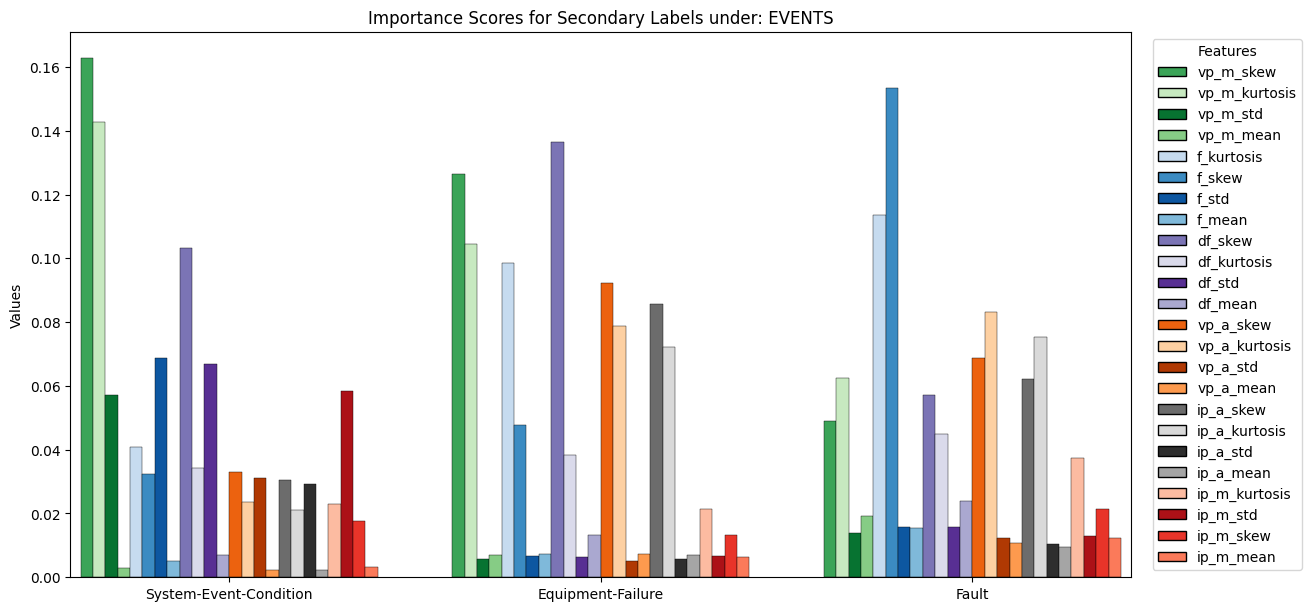


Processing PMU 1/1 - Primary Label: State


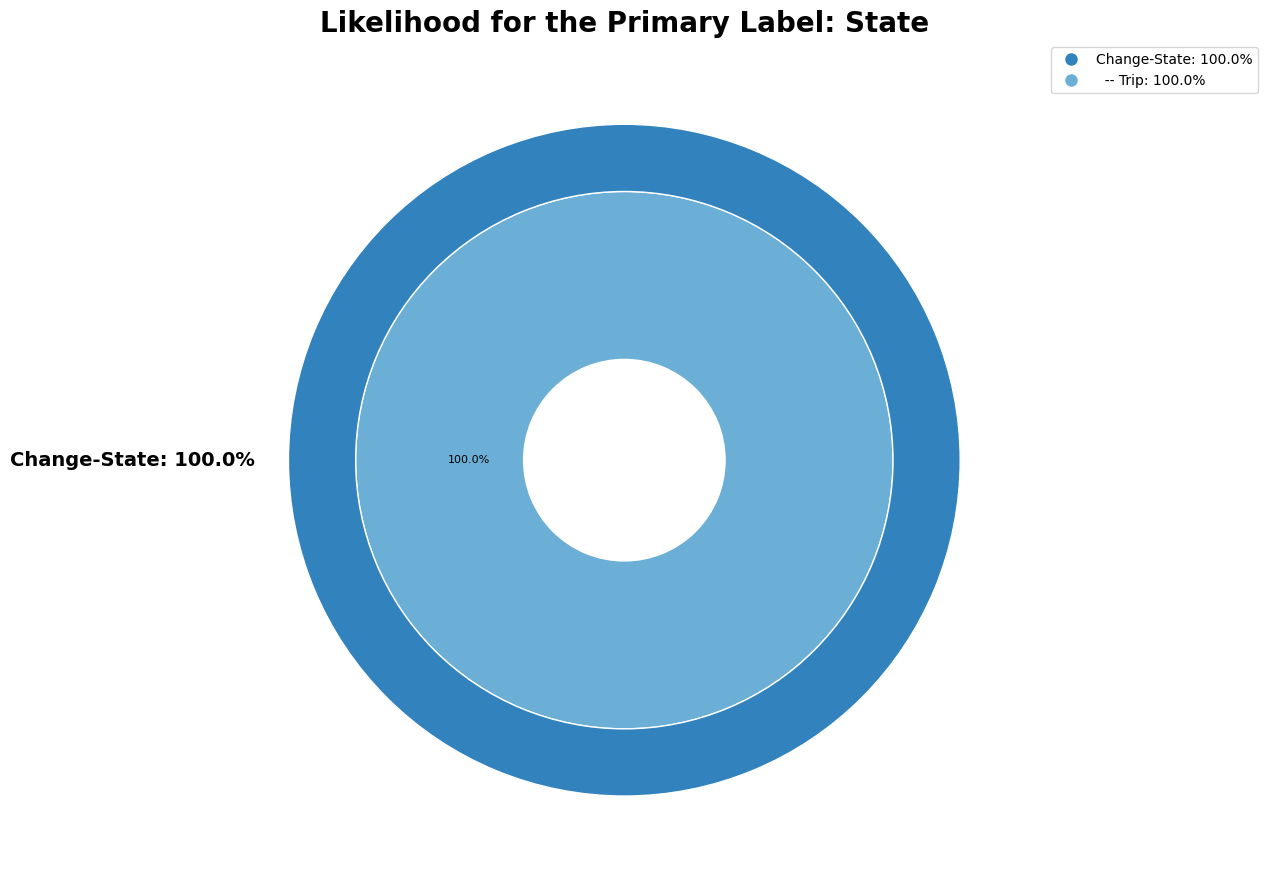


Secondary probabilities:


,label,raw_prob,adj_prob
0,Change-State,1.0,1.0



Tertiary probabilities:


,sec_label,tert_label,raw_prob,adj_prob
0,Change-State,Trip,1.0,1.0


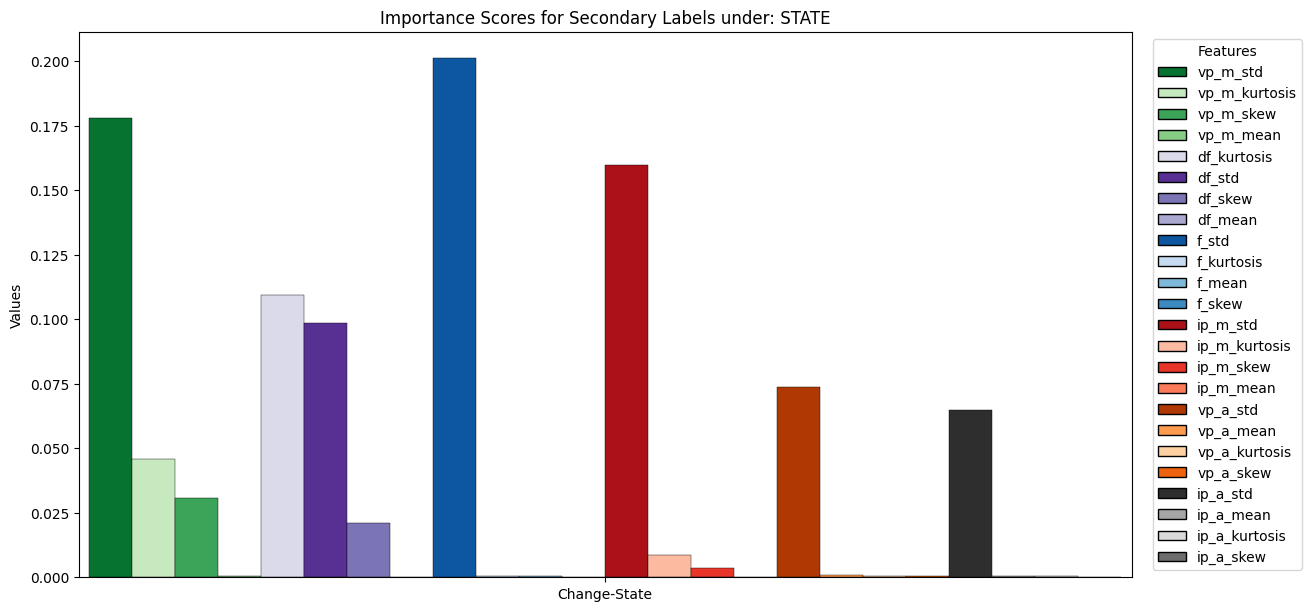


Processing PMU 1/1 - Primary Label: Equipment


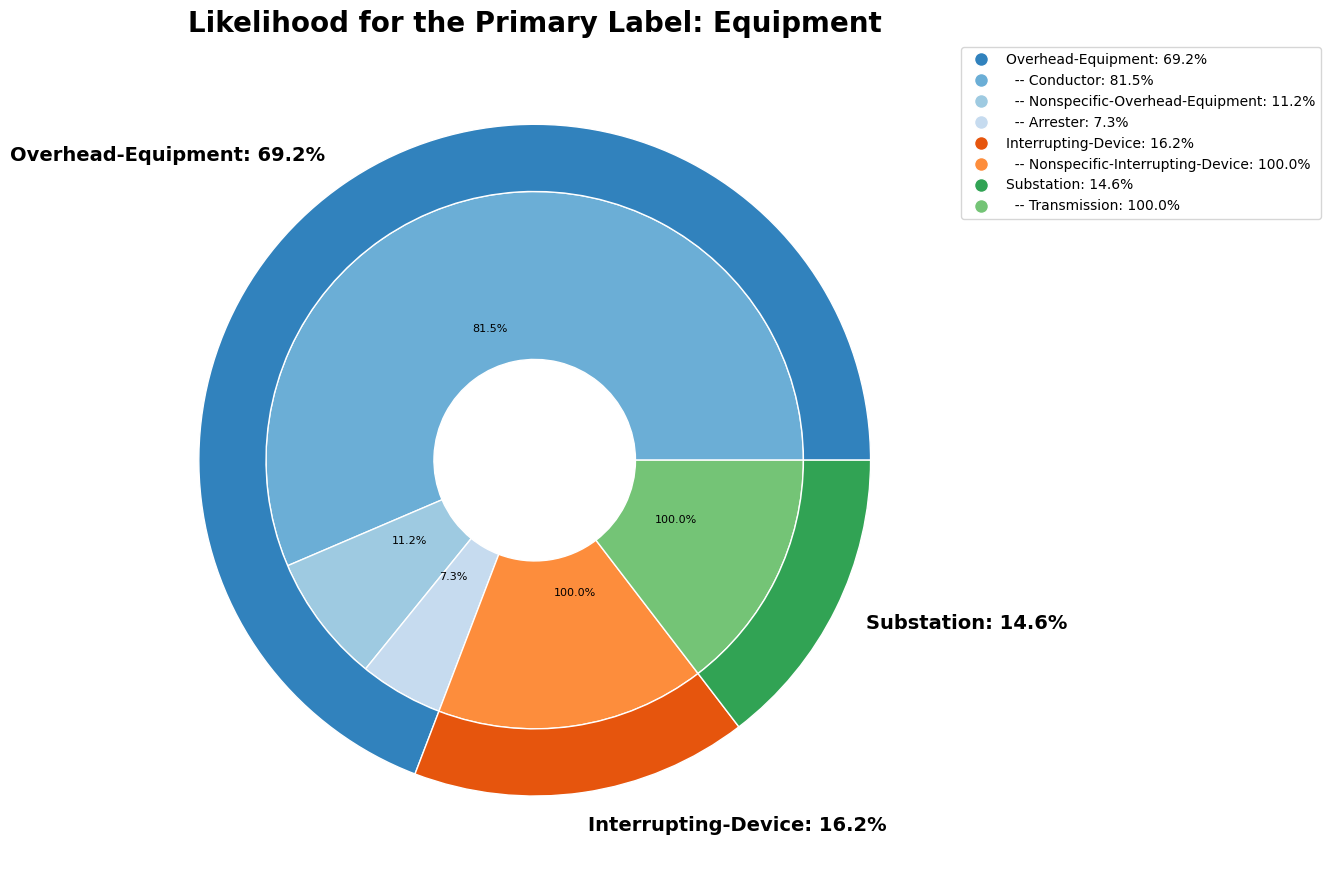


Secondary probabilities:


,label,raw_prob,adj_prob
0,Overhead-Equipment,0.755,0.644
1,Interrupting-Device,0.177,0.151
2,Substation,0.159,0.136



Tertiary probabilities:


,sec_label,tert_label,raw_prob,adj_prob
0,Overhead-Equipment,Conductor,0.734,0.815
1,Overhead-Equipment,Nonspecific-Overhead-Equipment,0.101,0.112
2,Overhead-Equipment,Arrester,0.066,0.073
0,Interrupting-Device,Nonspecific-Interrupting-Device,0.177,1.000
0,Substation,Transmission,0.159,1.000


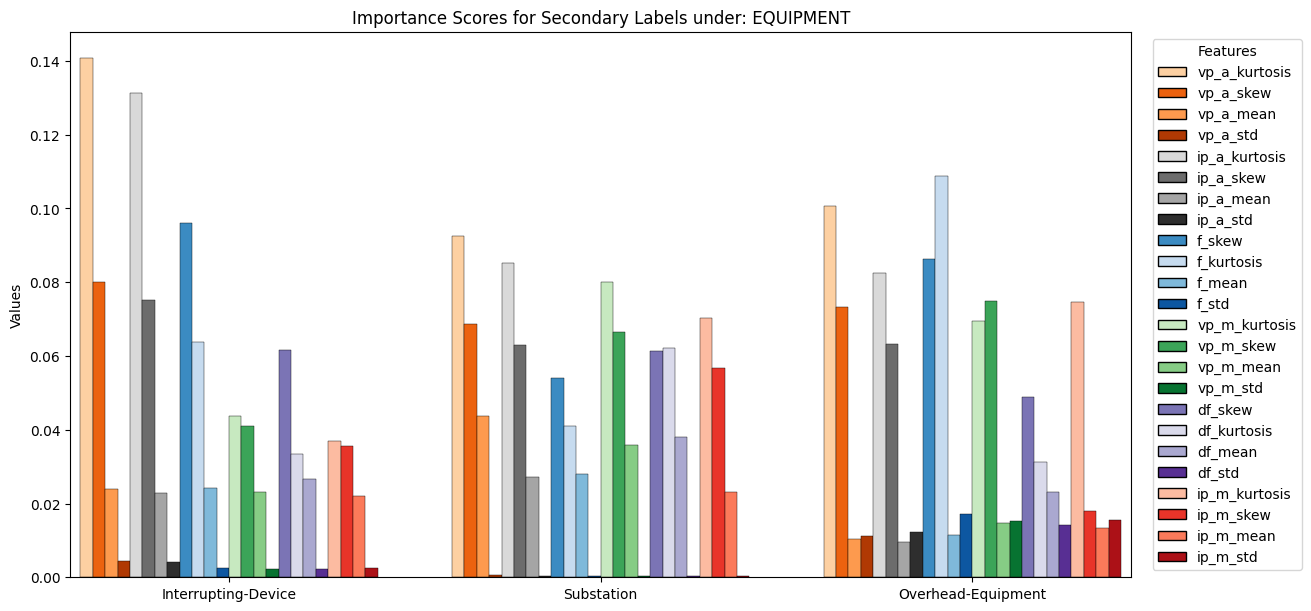


Processing PMU 1/1 - Primary Label: Conditions


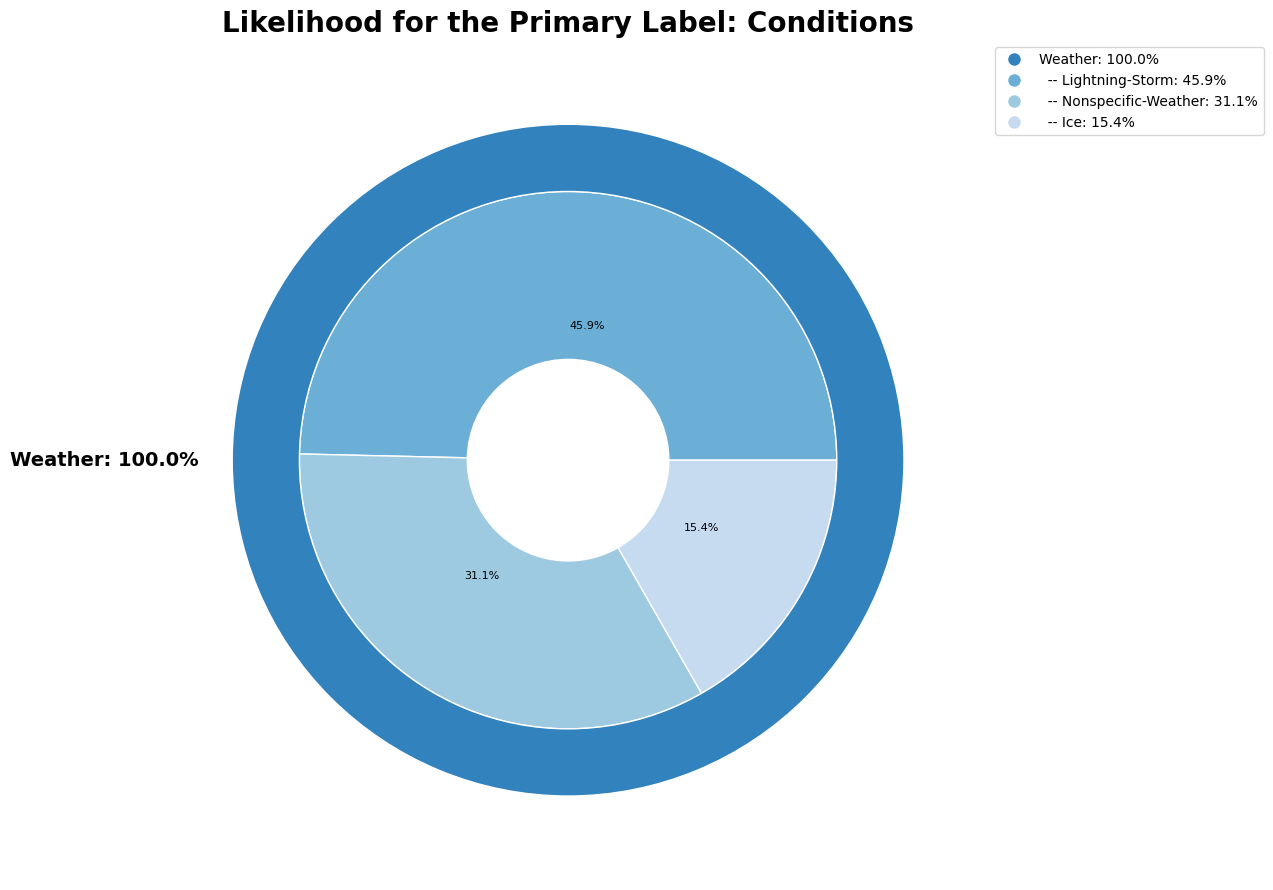


Secondary probabilities:


,label,raw_prob,adj_prob
0,Weather,0.974,1.0



Tertiary probabilities:


,sec_label,tert_label,raw_prob,adj_prob
0,Weather,Lightning-Storm,0.543,0.459
1,Weather,Nonspecific-Weather,0.368,0.311
2,Weather,Ice,0.183,0.155


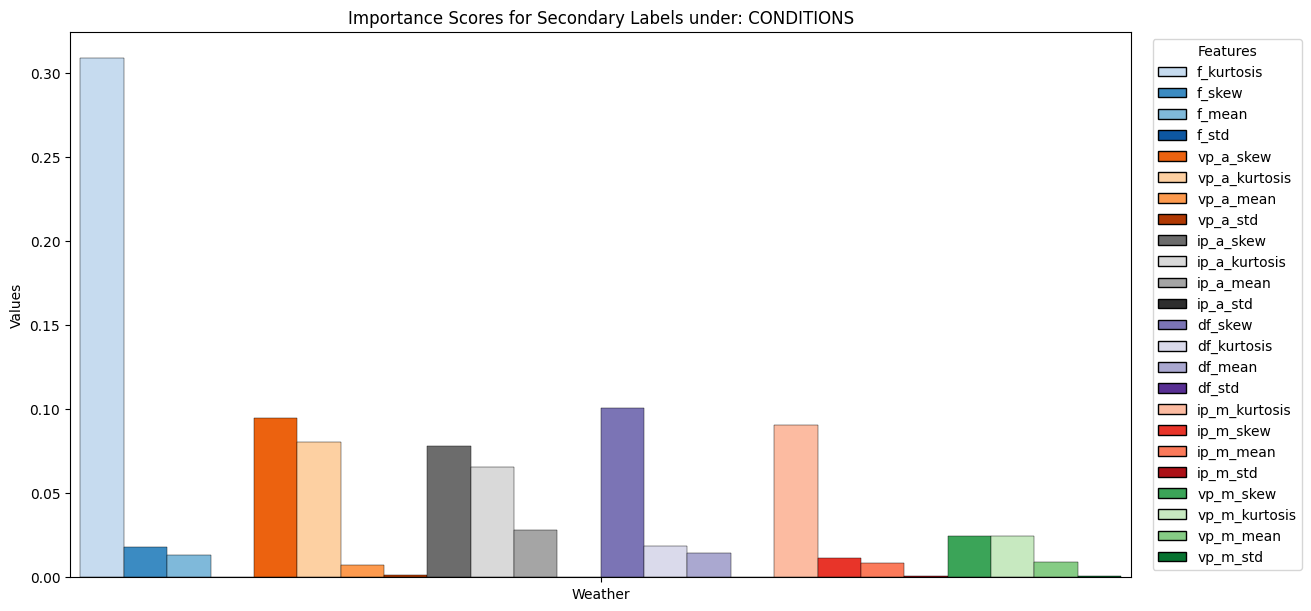


Processing PMU 1/1 - Primary Label: Phase


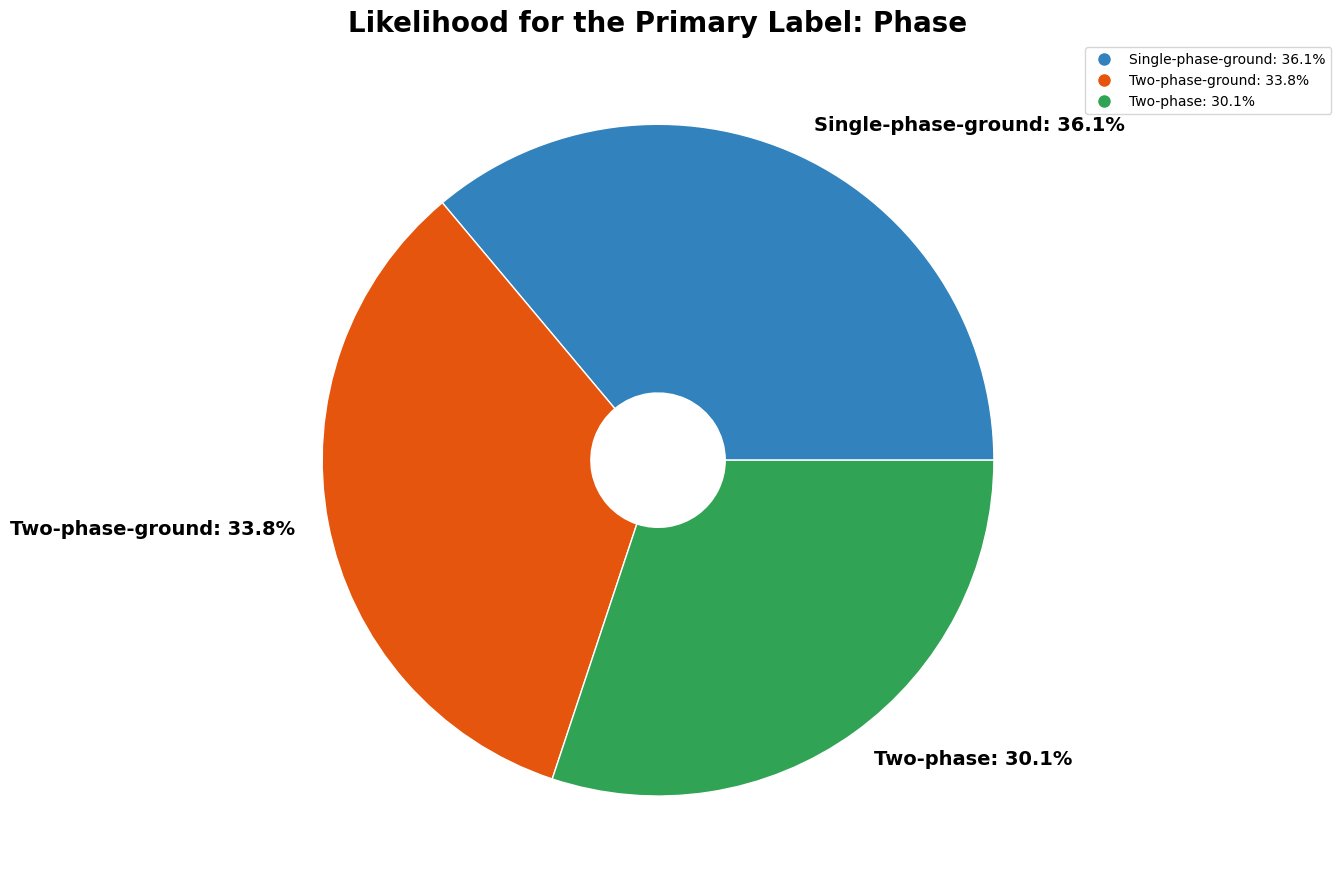


Secondary probabilities:


,label,raw_prob,adj_prob
0,Single-phase-ground,0.403,0.317
1,Two-phase-ground,0.377,0.297
2,Two-phase,0.335,0.264



Tertiary probabilities:


,sec_label,tert_label,raw_prob,adj_prob
0,Single-phase-ground,Phase-BG,0.256,0.334
1,Single-phase-ground,Nonspecific-Single-phase-ground,0.225,0.294
2,Single-phase-ground,Phase-AG,0.192,0.250
0,Two-phase-ground,Phases-ABG,0.210,0.383
3,Two-phase-ground,Nonspecific-Two-phase-ground,0.338,0.617
0,Two-phase,Phases-AB,0.214,0.458
1,Two-phase,Nonspecific-Two-phase,0.098,0.209
2,Two-phase,Phases-AC,0.156,0.333


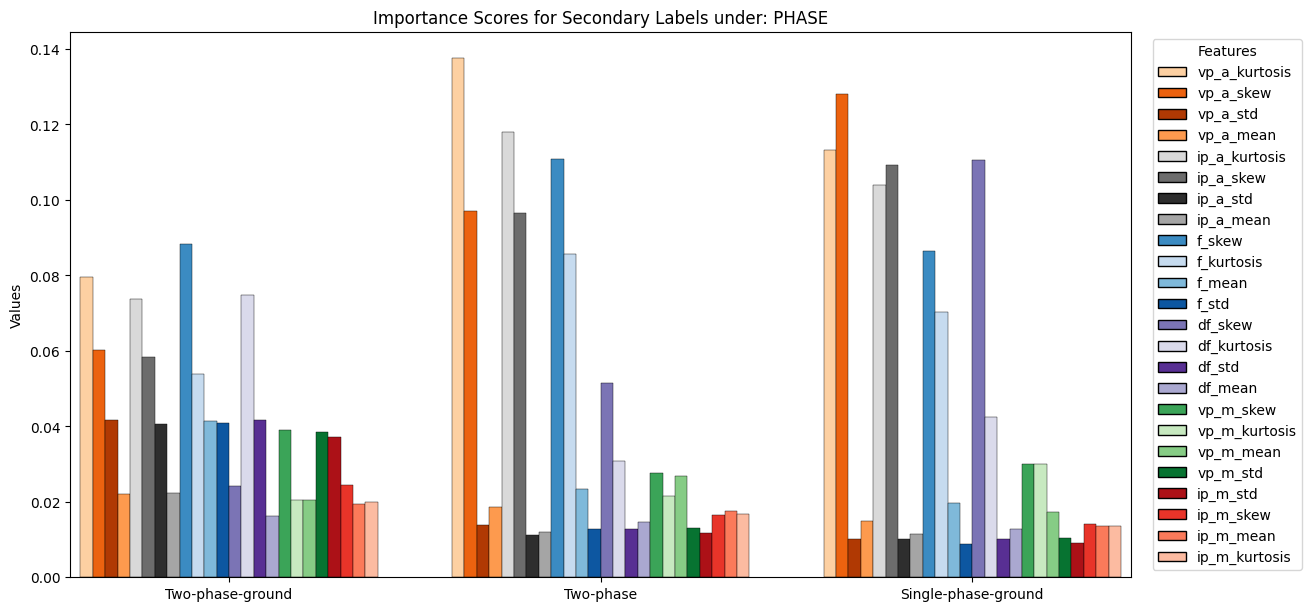


Analysis complete!


In [65]:
# Run the main analysis
if 'df_input' in locals() and 'pri_to_sec_dict' in locals() and 'sec_to_tert_dict' in locals():
    results = main()
    print("\nAnalysis complete!")
else:
    print("Please ensure all required data is loaded before running the analysis.")

In [ ]:
# Optional: Export results to file
if 'results' in locals():
    import datetime
    
    # Create timestamp for filename
    timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    
    # Save results to JSON
    output_filename = f"classification_results_{timestamp}.json"
    
    # Convert DataFrames to dictionaries for JSON serialization
    results_for_export = []
    for pmu_result in results:
        pmu_dict = {}
        for pri_label, data in pmu_result.items():
            pmu_dict[pri_label] = {
                'pred_class': data['pred_class'].to_dict(),
                'pred_subclass': data['pred_subclass'].to_dict(),
                'importance_scores': data['importance_scores']
            }
        results_for_export.append(pmu_dict)
    
    with open(output_filename, 'w') as f:
        json.dump(results_for_export, f, indent=2)
    
    print(f"Results saved to: {output_filename}")

Results saved to: classification_results_20250821_101646.json


In [ ]:
from pathlib import Path
import json
from copy import deepcopy

RAW_JSON = Path(f"classification_results_20250821_101646.json")
ROUNDED_JSON = Path("classification_results.json")

def round_floats(obj, ndigits=3):
    if isinstance(obj, float):
        r = round(obj, ndigits)
        return 0.0 if r == 0 else r
    if isinstance(obj, dict):
        return {k: round_floats(v, ndigits) for k, v in obj.items()}
    if isinstance(obj, list):
        return [round_floats(v, ndigits) for v in obj]
    return obj

with RAW_JSON.open("r", encoding="utf-8") as f:
    raw_payload = json.load(f)

rounded_payload = round_floats(deepcopy(raw_payload), ndigits=3)

with ROUNDED_JSON.open("w", encoding="utf-8") as f:
    json.dump(rounded_payload, f, indent=2)

print(f"Raw JSON kept at: {RAW_JSON}")
print(f"Rounded (3dp) JSON written to: {ROUNDED_JSON}")


Raw JSON kept at: classification_results_20250821_101646.json
Rounded (3dp) JSON written to: classification_results_cleaned_3dp.json
